# Task 3: การทำนายยอดใช้จ่าย 30 วัน (`spending_30d`)

## ภาพรวมของโจทย์และ metric

โจทย์นี้เป็น regression ที่ต้องทำนายยอดใช้จ่าย (บาท) ของผู้เล่นแต่ละคนในอีก 30 วันข้างหน้า คะแนนที่ใช้คือ

$$\text{score} = \frac{1}{1 + \text{NMAE}}, \qquad \text{NMAE} = \frac{\sum_i |y_i - \hat{y}_i|}{\sum_i y_i}$$

เนื่องจาก loss เป็น absolute error ค่าทำนายที่ดีที่สุดของผู้เล่นแต่ละคนคือ **median** ของการแจกแจงแบบมีเงื่อนไขของยอดใช้จ่าย ไม่ใช่ค่าเฉลี่ย แนวคิดนี้เป็นแกนของทั้ง pipeline

Pipeline สุดท้ายประกอบด้วย 3 components ที่นำมารวมกันแบบถ่วงน้ำหนัก

1. `hu`: hurdle model ที่ใช้ classifier ของ P(spend > 0) ร่วมกับ quantile models ของ log1p(spend) แล้วหา median ของ mixture
2. `lnL`: median ของ mixture ระหว่างศูนย์กับการแจกแจงแบบ log-normal โดยใช้ amount model ที่เริ่มจากสมการเชิงเส้น และ quantile ของ residual จริงจาก OOF
3. `r1`: LightGBM แบบ L1 ที่ทำนาย conditional median โดยตรงบนสเกลอัตราส่วน y / H

น้ำหนักของการรวมเลือกแยกกันระหว่างกลุ่ม whale (`segment == 3`) กับผู้เล่นกลุ่มอื่น โดยใช้ OOF ของ train เท่านั้น

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from t3_features import TARGET, SPEND_BINS, PURCHASE_COLS, nmae_score, impute, build_features, make_folds
from t3_models import (SEED, N_JOBS, fit_hurdle_pieces, fit_quantile_models, combine_quantile_hurdle,
                       combine_lognormal, design_fill_values, design, fit_linear_offset_amount, fit_ratio_l1,
                       lnmed, fit_select, C_GRID, SHIFT_GRID)

warnings.filterwarnings('ignore')
DATA = Path(os.environ.get('CPE342_DATA', '../data'))
OUT = Path('output'); OUT.mkdir(exist_ok=True)
np.random.seed(SEED)
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
T0 = time.time()
print(f'model seed {SEED}, LightGBM threads {N_JOBS}')

model seed 42, LightGBM threads 6


## การโหลดข้อมูล

In [2]:
train = pd.read_csv(DATA / '03_regression' / 'train.csv')
test = pd.read_csv(DATA / '03_regression' / 'test.csv')
y = train[TARGET].values
feats = [c for c in train.columns if c not in ('player_id', TARGET)]
sp = y > 0
print('train', train.shape, '| test', test.shape, '| features', len(feats))
print(train[TARGET].describe().round(2).to_string())

train (104000, 34) | test (25889, 33) | features 32
count    104000.00
mean      10497.04
std       30568.96
min           0.00
25%           0.00
50%          79.44
75%        2461.14
max      300000.00


## EDA: ลักษณะของ target

ก่อนเลือกวิธี ต้องดูว่า target มีรูปร่างอย่างไร สามประเด็นที่สำคัญต่อการออกแบบโมเดลคือ สัดส่วนผู้เล่นที่ไม่ใช้จ่ายเลย ความเบ้ทางขวาของยอดใช้จ่าย และการกระจุกตัวของยอดรวมในกลุ่ม segment 3

In [3]:
seg = train['segment']
print(f'สัดส่วน spending_30d = 0 : {np.mean(~sp):.3f}')
q = np.quantile(y[sp], [0.25, 0.5, 0.75, 0.9, 0.99])
print('quantiles ของผู้ใช้จ่าย (25/50/75/90/99%):', np.round(q, 1))
top = np.sort(y)[::-1]
print(f'ยอดรวมที่มาจากผู้เล่น top 1% : {top[:len(y)//100].sum() / y.sum():.3f}, top 10% : {top[:len(y)//10].sum() / y.sum():.3f}')
tab = (train.assign(seg=seg.fillna(-1).astype(int), spender=sp)
       .groupby('seg').agg(n=(TARGET, 'size'), zero_rate=('spender', lambda s: 1 - s.mean()),
                           median_spend=(TARGET, 'median'), mean_spend=(TARGET, 'mean'), total=(TARGET, 'sum')))
tab['share_of_total'] = tab['total'] / tab['total'].sum()
print(tab.drop(columns='total').round(3).to_string())

สัดส่วน spending_30d = 0 : 0.481
quantiles ของผู้ใช้จ่าย (25/50/75/90/99%): [   623.1   2314.   14453.4  74062.4 184398.6]
ยอดรวมที่มาจากผู้เล่น top 1% : 0.190, top 10% : 0.848
         n  zero_rate  median_spend  mean_spend  share_of_total
seg                                                            
-1    5935      0.468        125.56   11404.506           0.062
 0   39241      0.724          0.00      73.958           0.003
 1   24483      0.480        264.25     944.371           0.021
 2   19762      0.306       1837.64    2283.845           0.041
 3   14579      0.071      54760.28   65357.701           0.873


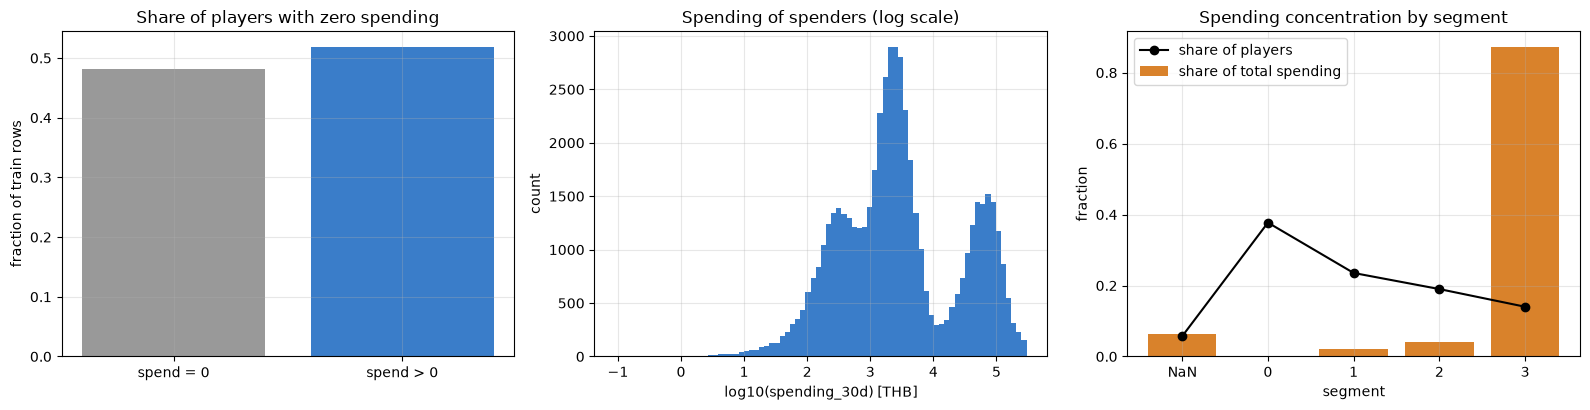

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(['spend = 0', 'spend > 0'], [np.mean(~sp), np.mean(sp)], color=['#999999', '#3a7dc9'])
ax[0].set_title('Share of players with zero spending'); ax[0].set_ylabel('fraction of train rows')
ax[1].hist(np.log10(y[sp]), bins=80, color='#3a7dc9')
ax[1].set_title('Spending of spenders (log scale)'); ax[1].set_xlabel('log10(spending_30d) [THB]'); ax[1].set_ylabel('count')
s_lab = ['NaN' if v == -1 else str(v) for v in tab.index]
ax[2].bar(s_lab, tab['share_of_total'], color='#d9822b', label='share of total spending')
ax[2].plot(s_lab, tab['n'] / tab['n'].sum(), 'ko-', label='share of players')
ax[2].set_title('Spending concentration by segment'); ax[2].set_xlabel('segment'); ax[2].set_ylabel('fraction'); ax[2].legend()
plt.tight_layout(); plt.show()

**สิ่งที่เห็นจาก EDA**

- ผู้เล่นราวครึ่งหนึ่ง (ประมาณ 48%) มียอดใช้จ่ายเป็นศูนย์ ดังนั้น target เป็นแบบ zero-inflated ถ้าโอกาสใช้จ่ายของผู้เล่นคนใดไม่เกิน 0.5 median ของเขาคือศูนย์พอดี จึงเหมาะกับโครงสร้างแบบ hurdle ที่แยก "จะใช้จ่ายหรือไม่" ออกจาก "ใช้จ่ายเท่าไร"
- ในกลุ่มที่ใช้จ่าย ยอดเงินกระจายกว้างหลายหลัก และ log ของยอดเงินมีรูปร่างใกล้ระฆัง จึงสร้างโมเดลของยอดเงินบนสเกล log
- segment 3 มีจำนวนผู้เล่นไม่มากแต่ครองยอดใช้จ่ายส่วนใหญ่ เนื่องจาก NMAE หารด้วยผลรวมของ y ความผิดพลาดของกลุ่มนี้มีผลต่อคะแนนมากที่สุด จึงเรียกกลุ่มนี้ว่า whale และเลือกน้ำหนักการรวมโมเดลแยกให้กลุ่มนี้

## การเตรียมข้อมูล: สร้างค่าที่หายไปจากสูตรที่แน่นอน

จากการสำรวจพบว่าคอลัมน์การซื้อ 5 คอลัมน์มีความสัมพันธ์แบบสูตรตรงตัว

- `historical_spending = avg_transaction_value * total_transactions` (ยกเว้นแถวที่ `total_transactions = 0` ซึ่งเก็บ `avg_transaction_value = historical_spending`)
- `discount_rate_used = purchases_on_discount / total_transactions`

ดังนั้นเมื่อคอลัมน์ใดหายไป สามารถคำนวณกลับจากคอลัมน์อื่นในแถวเดียวกันได้ (ฟังก์ชัน `impute` วนซ้ำ 3 รอบ เพื่อให้ค่าที่เติมแล้วช่วยเติมค่าอื่นต่อ) การแปลงนี้ใช้เฉพาะข้อมูลในแถวนั้น จึงทำแยกกันระหว่าง train กับ test โดยไม่ใช้สถิติใดจาก test เซลล์ด้านล่างตรวจสอบว่าสูตรเป็นจริงในแถวที่ข้อมูลครบ และนับค่าที่หายไปก่อนและหลังการเติม

In [5]:
c = train[PURCHASE_COLS].dropna()
pos = c['total_transactions'] > 0
rel1 = (np.abs(c['historical_spending'] - c['avg_transaction_value'] * c['total_transactions'])[pos]
        / c['historical_spending'][pos].clip(lower=1e-9))
rel2 = np.abs(c['discount_rate_used'] - c['purchases_on_discount'] / c['total_transactions'])[pos]
print(f'แถวที่ครบทั้ง 5 คอลัมน์: {len(c)} (tx > 0: {pos.sum()})')
print(f'hist = atv * tx : median relative error {rel1.median():.2e}, 99th pct {rel1.quantile(0.99):.2e}')
print(f'dr = pod / tx   : median abs error {rel2.median():.2e}, 99th pct {rel2.quantile(0.99):.2e}')
print(f'tx = 0 rows: atv == hist in {np.mean(np.isclose(c.loc[~pos, "avg_transaction_value"], c.loc[~pos, "historical_spending"])):.3f} of rows')

miss = pd.DataFrame({'train_before': train[PURCHASE_COLS].isna().sum(), 'train_after': impute(train[feats])[PURCHASE_COLS].isna().sum(),
                     'test_before': test[PURCHASE_COLS].isna().sum(), 'test_after': impute(test[feats])[PURCHASE_COLS].isna().sum()})
print(miss.to_string())

แถวที่ครบทั้ง 5 คอลัมน์: 77010 (tx > 0: 76240)
hist = atv * tx : median relative error 0.00e+00, 99th pct 1.62e-16
dr = pod / tx   : median abs error 0.00e+00, 99th pct 0.00e+00
tx = 0 rows: atv == hist in 1.000 of rows
                       train_before  train_after  test_before  test_after
historical_spending            6035          393         1506          95
avg_transaction_value          5991          410         1569          98
total_transactions             6067          109         1465          21
purchases_on_discount          6083          360         1505          95
discount_rate_used             6103          430         1552         110


### ฟีเจอร์เพิ่มเติม

นอกจากคอลัมน์เดิมทั้ง 32 คอลัมน์ (ไม่ใช้ `player_id`) ได้เพิ่มฟีเจอร์แบบ row-wise ดังนี้

- `log_hist`, `log_prev`: log ของ `historical_spending` และ `prev_month_spending`
- `log_hp = 0.63 * log_hist + 0.37 * log_prev` เป็นจุดยึดเชิงเส้นบนสเกล log ของยอดใช้จ่าย ถ้าค่าใดค่าหนึ่งหายไปจะใช้อีกค่าแทน (โดยประมาณ prev มีค่าราว 0.35 เท่าของ hist)
- `hist_x_prev = historical_spending + prev_month_spending` และ `tx_value_x_freq = avg_transaction_value * purchase_frequency`

X (104000, 37) | Xt (25889, 37)
corr(log y, log_hp) ในกลุ่มผู้ใช้จ่าย: 0.9819
missing log_hp: train 27, test 4


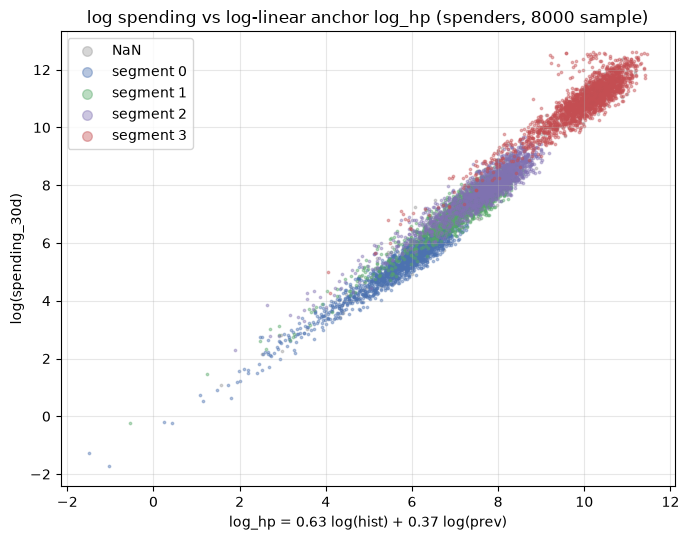

In [6]:
X = build_features(train, feats)
Xt = build_features(test, feats)
ly = np.log(np.clip(y, 1e-3, None))
print('X', X.shape, '| Xt', Xt.shape)
ok = sp & X['log_hp'].notna().values
print(f'corr(log y, log_hp) ในกลุ่มผู้ใช้จ่าย: {np.corrcoef(ly[ok], X["log_hp"].values[ok])[0, 1]:.4f}')
print(f'missing log_hp: train {X["log_hp"].isna().sum()}, test {Xt["log_hp"].isna().sum()}')

rng = np.random.default_rng(0); idx = rng.choice(np.where(ok)[0], 8000, replace=False)
segv = X['segment'].fillna(-1).values[idx]
fig, ax = plt.subplots(figsize=(7, 5.5))
for s_, col in zip([-1, 0, 1, 2, 3], ['#999999', '#4c72b0', '#55a868', '#8172b2', '#c44e52']):
    m_ = segv == s_
    ax.scatter(X['log_hp'].values[idx][m_], ly[idx][m_], s=3, alpha=0.4, color=col, label='NaN' if s_ == -1 else f'segment {s_}')
ax.set_title('log spending vs log-linear anchor log_hp (spenders, 8000 sample)')
ax.set_xlabel('log_hp = 0.63 log(hist) + 0.37 log(prev)'); ax.set_ylabel('log(spending_30d)'); ax.legend(markerscale=4)
plt.tight_layout(); plt.show()

กราฟแสดงว่าในกลุ่มผู้ใช้จ่าย log ของยอดใช้จ่ายเกือบเป็นเส้นตรงกับ `log_hp` และแต่ละ segment เรียงตัวเป็นแถบขนานกันแต่เลื่อนระดับ นี่คือเหตุผลที่ amount model ทุกตัวใช้ `log_hp` (หรือสมการเชิงเส้นที่ขยายจากมัน) เป็นจุดเริ่มต้น แล้วให้ LightGBM เรียนรู้เฉพาะส่วนที่เหลือ วิธีนี้ช่วยให้โมเดลต้นไม้ทำนายผู้เล่นยอดสูงมากได้ดีขึ้น เพราะต้นไม้เพียงอย่างเดียว extrapolate นอกช่วงข้อมูลไม่ได้

## การแบ่ง fold สำหรับ Cross-validation

ทุก component ใช้ fold ชุดเดียวกัน คือ `StratifiedKFold(5, shuffle=True, random_state=42)` โดย stratify ตามช่วงยอดใช้จ่าย `[0.01, 100, 1000, 10000, 50000]` เพื่อให้แต่ละ fold มีผู้เล่นศูนย์และ whale ในสัดส่วนเท่ากัน ค่าทำนายของ test คือค่าเฉลี่ยของโมเดลทั้ง 5 folds

In [7]:
folds = make_folds(y, 42)
fid = np.zeros(len(y), int)
for k, (_, va) in enumerate(folds):
    fid[va] = k
strat = np.digitize(y, SPEND_BINS)
print(pd.crosstab(fid, strat, rownames=['fold'], colnames=['spend bin']).to_string())

spend bin      0    1     2     3     4     5
fold                                         
0          10010  501  2822  4652  1118  1697
1          10010  501  2822  4652  1118  1697
2          10010  501  2822  4652  1118  1697
3          10010  502  2823  4652  1117  1696
4          10009  502  2823  4653  1117  1696


## โมเดล

### ส่วนประกอบร่วม: P(spend > 0), log-amount model และ spread model

ทุก fold ฝึกโมเดล LightGBM 3 ตัว (learning rate 0.03, num_leaves 63, early stopping 150 รอบบน fold ที่ถือออก)

1. **binary classifier** ของ P(spend > 0) บนทุกแถว ได้ค่า `p`
2. **L2 model ของ log(spend)** เฉพาะผู้ใช้จ่าย โดยใช้ `log_hp` เป็น `init_score` ได้ค่า `mu`
3. **spread model** (num_leaves 15, learning rate 0.05) ทำนาย |residual บนสเกล log| แล้วคูณ sqrt(pi/2) ซึ่งเท่ากับ standard deviation เมื่อ residual แจกแจงแบบปกติ ได้ค่า `s`

จาก `p`, `mu` และ `s` หาค่าที่ทำให้ absolute error ต่ำสุดได้ คือ median ของ mixture ถ้า p <= 0.5 คำตอบคือ 0 มิฉะนั้นคำตอบคือ quantile ระดับ (p - 0.5) / p ของการแจกแจงยอดเงินของผู้ใช้จ่าย

In [8]:
t = time.time()
R, T, it = fit_hurdle_pieces(X, Xt, y, folds, seed=SEED)
print(f'train time {time.time() - t:.0f}s | best iterations (clf, mu, spread) per fold: {it}')
print(f'P(spend > 0): OOF AUC {roc_auc_score(sp, R["p"]):.4f}, accuracy at 0.5 {np.mean((R["p"] > 0.5) == sp):.4f}')
r_mu = ly[sp] - R['mu'][sp]
print(f'log-amount (log_hp init): spender mean|resid| {np.mean(np.abs(r_mu)):.4f}, median|resid| {np.median(np.abs(r_mu)):.4f}')
ln_norm = combine_lognormal(R['p'], R['mu'], R['s'])
print(f'zero / log-normal median (normal quantiles): OOF score {nmae_score(y, ln_norm):.5f}')

train time 324s | best iterations (clf, mu, spread) per fold: [(124, 649, 81), (118, 824, 204), (156, 820, 107), (175, 1157, 279), (144, 1071, 409)]
P(spend > 0): OOF AUC 0.7844, accuracy at 0.5 0.7194
log-amount (log_hp init): spender mean|resid| 0.1387, median|resid| 0.1169


zero / log-normal median (normal quantiles): OOF score 0.78967


### Component `hu`: hurdle กับ quantile models

แทนที่จะสมมุติว่า log ของยอดเงินแจกแจงแบบปกติ component นี้ฝึก LightGBM แบบ quantile 11 ระดับ (0.05 ถึง 0.95) บน log1p(spend) ของผู้ใช้จ่าย แล้ว interpolate quantile curve ของแต่ละแถวที่ระดับ (p - 0.5) / p โดยใช้ `p` จาก classifier ข้างบน (เป็น classifier ที่ hyperparameters, fold และ seed เดียวกัน)

In [9]:
t = time.time()
oof_q, test_q = fit_quantile_models(X, Xt, y, folds, seed=SEED)
hu = np.clip(combine_quantile_hurdle(R['p'], oof_q), 0, None)
hut = np.clip(combine_quantile_hurdle(T['p'], test_q), 0, None)
print(f'train time {time.time() - t:.0f}s | hu OOF score {nmae_score(y, hu):.5f}')

train time 1946s | hu OOF score 0.79062


### Amount model ที่เริ่มจากสมการเชิงเส้น (ใช้แทน `mu` เดิม)

`log_hp` เป็นจุดเริ่มต้นที่ดี แต่ยังไม่รวมผลของ segment, vip_status และคอลัมน์อื่นที่สัมพันธ์เชิงเส้นกับ log(spend) จึงสร้าง design matrix จาก `log_hp`, flag ของค่าที่หายไป, log ของ event participation และ purchase frequency, games_played, premium, log ของ days since last purchase และ dummy ของ segment x vip_status จากนั้นในแต่ละ fold

1. fit least squares บนผู้ใช้จ่ายใน training fold
2. fit ซ้ำโดยใช้เฉพาะแถวที่ |residual| < 0.6 (trimmed least squares ลดอิทธิพลของ outlier)
3. ใช้ค่าจากสมการเป็น `init_score` ของ LightGBM แบบ L2 (early stopping 200 รอบ)

ค่าที่ใช้เติม `log_hp` และ `games_played` ที่หายไปใน design matrix คือ median ของ train และใช้ค่าเดียวกันกับ test

In [10]:
fill = design_fill_values(X)
D, Dt = design(X, fill), design(Xt, fill)
print('fill values (train medians):', {k: round(v, 4) for k, v in fill.items()}, '| design matrix', D.shape)
t = time.time()
mu_lin, mut_lin, it = fit_linear_offset_amount(X, Xt, y, folds, D, Dt, seed=SEED)
print(f'train time {time.time() - t:.0f}s | best iterations per fold: {it}')
r_lin = ly[sp] - mu_lin[sp]; core = np.abs(r_lin) < 0.6
print(f'spender mean|resid| {np.mean(np.abs(r_lin)):.4f} (log_hp init {np.mean(np.abs(r_mu)):.4f}), '
      f'median|resid| {np.median(np.abs(r_lin)):.4f}, core sd {r_lin[core].std():.4f}')

fill values (train medians): {'log_hp': 6.9771, 'games_played': 2.0} | design matrix (104000, 45)


train time 30s | best iterations per fold: [385, 460, 407, 576, 632]
spender mean|resid| 0.1371 (log_hp init 0.1387), median|resid| 0.1159, core sd 0.1555


### Component `r1`: L1 LightGBM บนสเกลอัตราส่วน

component นี้ทำนาย conditional median โดยตรง ให้ H = exp(`log_hp`) แล้วฝึก LightGBM แบบ L1 บน target y / H โดยใช้ weight H ซึ่งทำให้ weighted L1 loss เท่ากับ sum |y - H r| พอดี กล่าวคือ minimize absolute error บนสเกลเงินจริง แต่ต้นไม้เรียนรู้บนสเกลอัตราส่วนที่ไม่ขึ้นกับขนาดของผู้เล่น (learning rate 0.05, num_leaves 31, early stopping 200) ค่า `log_hp` ที่หายไปเติมด้วย median ของ H จาก train

In [11]:
t = time.time()
r1, r1t, it = fit_ratio_l1(X, Xt, y, folds, seed=SEED)
print(f'train time {time.time() - t:.0f}s | best iterations per fold: {it} | r1 OOF score {nmae_score(y, r1):.5f}')

train time 93s | best iterations per fold: [293, 276, 419, 399, 289] | r1 OOF score 0.79093


## Component `lnL`: median ของ mixture ด้วย quantile ของ residual จริง

ใช้ `p` และ `s` จากส่วนประกอบร่วม และใช้ `mu` จาก amount model เชิงเส้น จาก OOF พบว่า residual มาตรฐาน z = (log y - mu) / s ไม่ได้แจกแจงแบบปกติพอดี จึงใช้ quantile เชิงประจักษ์ของ z จากผู้ใช้จ่ายใน OOF ของ train (Q_z) แทน `norm.ppf`

$$\hat{y} = \begin{cases} 0 & p' \le 0.5 \\ \exp\left(\mu + c \cdot s \cdot Q_z\!\left(\frac{p' - 0.5}{p'}\right)\right) & p' > 0.5 \end{cases}, \qquad p' = p + \text{shift}$$

พารามิเตอร์ c (ขยาย spread) และ shift (ปรับ P(spend > 0)) ใช้แก้ bias ที่เหลือของ spread model และ classifier โดยเลือกจาก grid c ใน {1.0, 1.1, 1.2, 1.3, 1.4} และ shift ใน {-0.03, -0.015, 0, 0.015} ตามคะแนน OOF

standardized residual z (spenders): mean 0.001, sd 1.511, quantiles 5/50/95% [-2.029 -0.032  1.877]


OOF score grid (rows c, columns shift):
shift   -0.030   -0.015    0.000    0.015
c                                        
1.0    0.79238  0.79239  0.79229  0.79215
1.1    0.79238  0.79242  0.79236  0.79223
1.2    0.79234  0.79243  0.79239  0.79229
1.3    0.79227  0.79240  0.79240  0.79233
1.4    0.79216  0.79234  0.79239  0.79235


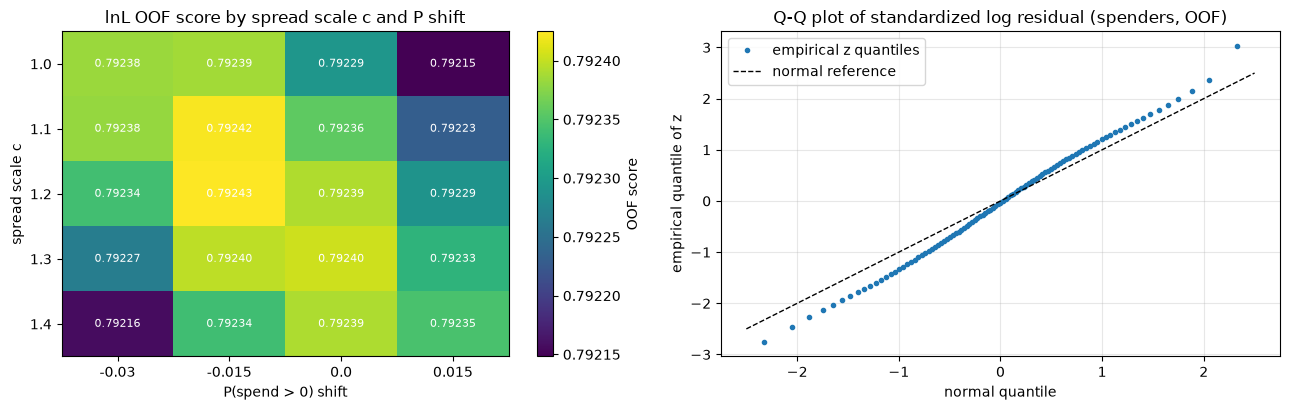

In [12]:
p, s, mu = R['p'], np.clip(R['s'], 0.05, 2), mu_lin
pt, st, mut = T['p'], np.clip(T['s'], 0.05, 2), mut_lin
z = (ly - mu) / s
zs_all = z[sp]
print(f'standardized residual z (spenders): mean {zs_all.mean():.3f}, sd {zs_all.std():.3f}, '
      f'quantiles 5/50/95% {np.round(np.quantile(zs_all, [0.05, 0.5, 0.95]), 3)}')
grid = pd.DataFrame([[nmae_score(y, lnmed(p, mu, s, zs_all, c_, ps_)) for ps_ in SHIFT_GRID] for c_ in C_GRID],
                    index=pd.Index(C_GRID, name='c'), columns=pd.Index(SHIFT_GRID, name='shift'))
print('OOF score grid (rows c, columns shift):'); print(grid.round(5).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
im = ax[0].imshow(grid.values, cmap='viridis', aspect='auto')
ax[0].set_xticks(range(len(SHIFT_GRID)), [str(v) for v in SHIFT_GRID]); ax[0].set_yticks(range(len(C_GRID)), [str(v) for v in C_GRID])
for i in range(len(C_GRID)):
    for j in range(len(SHIFT_GRID)):
        ax[0].text(j, i, f'{grid.values[i, j]:.5f}', ha='center', va='center', color='w', fontsize=8)
ax[0].set_title('lnL OOF score by spread scale c and P shift'); ax[0].set_xlabel('P(spend > 0) shift'); ax[0].set_ylabel('spread scale c')
ax[0].grid(False); fig.colorbar(im, ax=ax[0], label='OOF score')
qq = np.linspace(0.01, 0.99, 99)
ax[1].plot(norm.ppf(qq), np.quantile(zs_all, qq), 'o', ms=3, label='empirical z quantiles')
ax[1].plot([-2.5, 2.5], [-2.5, 2.5], 'k--', lw=1, label='normal reference')
ax[1].set_title('Q-Q plot of standardized log residual (spenders, OOF)'); ax[1].set_xlabel('normal quantile'); ax[1].set_ylabel('empirical quantile of z')
ax[1].legend(); plt.tight_layout(); plt.show()

Q-Q plot แสดงว่า residual มาตรฐานมีรูปร่างต่างจากการแจกแจงปกติ (จุดไม่อยู่บนเส้นอ้างอิง) การใช้ quantile เชิงประจักษ์จึงให้ median ของ mixture ที่ตรงกับข้อมูลมากกว่า ตาราง grid แสดงคะแนนของ `lnL` เมื่อเลือก c และ shift บน OOF ทั้งหมด ส่วนขั้นตอนการรวมโมเดลด้านล่างเลือก c และ shift ซ้ำภายใน nested CV เพื่อไม่ให้คะแนนสูงเกินจริง

## การรวมโมเดลแยกกลุ่ม whale

รวม 3 components ด้วยน้ำหนักบน simplex grid ละเอียด 0.1 ([w_hu, w_lnL, w_r1] ไม่ติดลบและรวมกันเท่ากับ 1) โดยเลือกน้ำหนักแยกสำหรับ whale (`segment == 3`) กับผู้เล่นที่เหลือ เพราะ whale มีสัดส่วนต่อ NMAE สูงและพฤติกรรมของ residual ต่างจากกลุ่มอื่น

เพื่อประเมินคะแนนอย่างตรงไปตรงมา ใช้ **nested CV**: สำหรับแต่ละ fold k เลือก (c, shift), แหล่ง quantile ของ z และน้ำหนัก จาก OOF ของอีก 4 folds แล้วนำไปใช้กับ fold k จากนั้นจึงเลือกพารามิเตอร์ชุดสุดท้ายบน OOF ทั้งหมดเพื่อใช้กับ test

In [13]:
whale = (X['segment'].values == 3).astype(int)
whale_t = (Xt['segment'].values == 3).astype(int)
oof_nested = np.zeros(len(y)); picks = []
for k in range(5):
    g, zs, ws, M = fit_select(fid != k, y, sp, p, mu, s, z, hu, r1, whale)
    for gv in (0, 1):
        o = (fid == k) & (whale == gv)
        oof_nested[o] = M[o] @ ws[gv]
    picks.append({'fold': k, 'c': g[0], 'shift': g[1], 'w_rest': ws[0].tolist(), 'w_whale': ws[1].tolist()})
print(pd.DataFrame(picks).to_string(index=False))
print(f'nested-CV blend OOF score: {nmae_score(y, oof_nested):.5f}')

 fold   c  shift          w_rest         w_whale
    0 1.2 -0.015 [0.5, 0.5, 0.0] [0.1, 0.5, 0.4]
    1 1.2 -0.015 [0.5, 0.5, 0.0] [0.1, 0.5, 0.4]
    2 1.2 -0.015 [0.5, 0.5, 0.0] [0.0, 0.5, 0.5]
    3 1.2 -0.015 [0.5, 0.5, 0.0] [0.1, 0.5, 0.4]
    4 1.1 -0.015 [0.6, 0.4, 0.0] [0.1, 0.5, 0.4]
nested-CV blend OOF score: 0.79356


In [14]:
g, zs, ws, M = fit_select(np.ones(len(y), bool), y, sp, p, mu, s, z, hu, r1, whale)
C_SEL, SHIFT_SEL = g
lnL = M[:, 1]
oof_full = np.where(whale == 1, M @ ws[1], M @ ws[0])
print(f'chosen on full OOF: c = {C_SEL}, shift = {SHIFT_SEL}')
print(f'weights [hu, lnL, r1]: rest = {ws[0].tolist()}, whale = {ws[1].tolist()}')
print(f'full-OOF blend score (parameters chosen on the same OOF): {nmae_score(y, oof_full):.5f}')

def grp_score(pred, m_):
    return 1 / (1 + np.abs(y[m_] - pred[m_]).sum() / y[m_].sum())
rows = []
for name, pred in [('lognormal (normal z)', ln_norm), ('hu', hu), ('lnL', lnL), ('r1', r1),
                   ('blend (nested)', oof_nested), ('blend (full-OOF fit)', oof_full)]:
    rows.append({'model': name, 'OOF score': nmae_score(y, pred), 'rest (seg != 3)': grp_score(pred, whale == 0),
                 'whale (seg == 3)': grp_score(pred, whale == 1)})
summary = pd.DataFrame(rows).set_index('model')
print(summary.round(5).to_string())

chosen on full OOF: c = 1.2, shift = -0.015
weights [hu, lnL, r1]: rest = [0.5, 0.5, 0.0], whale = [0.1, 0.5, 0.4]
full-OOF blend score (parameters chosen on the same OOF): 0.79360
                      OOF score  rest (seg != 3)  whale (seg == 3)
model                                                             
lognormal (normal z)    0.78967          0.69971           0.80475
hu                      0.79062          0.70099           0.80563
lnL                     0.79243          0.70079           0.80782
r1                      0.79093          0.69345           0.80747
blend (nested)          0.79356          0.70263           0.80882
blend (full-OOF fit)    0.79360          0.70266           0.80885


ตารางสรุปคะแนน OOF ของแต่ละ component และของการรวม (คะแนนรายกลุ่มคำนวณจาก NMAE ภายในกลุ่มนั้น) การรวมโมเดลดีกว่า component ที่ดีที่สุดเพียงตัวเดียว เพราะ `hu`, `lnL` และ `r1` ผิดพลาดในแถวที่ต่างกัน สำหรับผู้เล่นทั่วไป `hu` กับ `lnL` เสริมกันได้ดี ส่วนในกลุ่ม whale ซึ่งยอดเงินสูงมาก `r1` ที่ minimize absolute error บนสเกลเงินจริงโดยตรงได้น้ำหนักสูงขึ้น

ต่อไปประเมินความไม่แน่นอนของคะแนนด้วย bootstrap ของแถว OOF เพื่อดูว่าความต่างระดับทศนิยมตำแหน่งที่ 4 มีความหมายเพียงใด

In [15]:
rng = np.random.default_rng(0)
e_b, e_h = np.abs(y - oof_nested), np.abs(y - hu)
bs, bd = [], []
for _ in range(500):
    i = rng.integers(0, len(y), len(y)); sy = y[i].sum()
    bs.append(1 / (1 + e_b[i].sum() / sy)); bd.append(bs[-1] - 1 / (1 + e_h[i].sum() / sy))
print(f'bootstrap sd of nested blend score: {np.std(bs):.5f}')
print(f'blend - hu: {nmae_score(y, oof_nested) - nmae_score(y, hu):+.5f} (bootstrap sd of the difference {np.std(bd):.5f})')

bootstrap sd of nested blend score: 0.00191
blend - hu: +0.00295 (bootstrap sd of the difference 0.00028)


bootstrap sd ของคะแนนรวมอยู่ที่ประมาณ 0.002 ซึ่งใหญ่กว่าส่วนต่างระหว่าง component ที่ดีที่สุดหลายตัว แปลว่าคะแนนบน test ชุดอื่นอาจขยับได้ในระดับนี้จากความสุ่มของตัวอย่างเพียงอย่างเดียว อย่างไรก็ตาม เมื่อเปรียบเทียบแบบจับคู่บนแถวเดียวกัน การรวมโมเดลดีกว่า `hu` ราว 0.003 โดยมี sd ของส่วนต่างเพียงประมาณ 0.0003 จึงเป็นการปรับปรุงที่สม่ำเสมอจริง แม้ขนาดจะเล็ก

### การตรวจสอบค่าทำนาย OOF

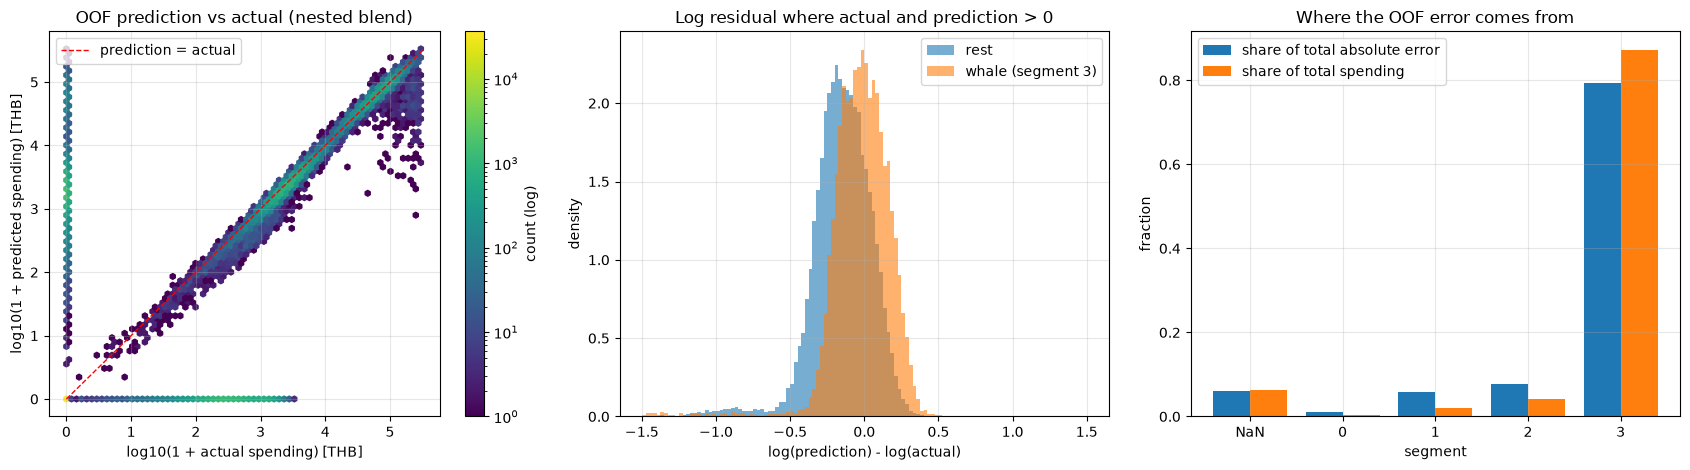

จริง = 0 แต่ทำนาย > 0: 0.128 ของแถว | จริง > 0 แต่ทำนาย 0: 0.153 ของแถว
สัดส่วน absolute error จากแถวที่ทำนาย 0 แต่จริง > 0: 0.027
log residual (จริงและทำนาย > 0): median |res| 0.1426


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
hb = ax[0].hexbin(np.log10(y + 1), np.log10(oof_nested + 1), gridsize=70, bins='log', cmap='viridis', mincnt=1)
ax[0].plot([0, 5.5], [0, 5.5], 'r--', lw=1, label='prediction = actual')
ax[0].set_title('OOF prediction vs actual (nested blend)'); ax[0].set_xlabel('log10(1 + actual spending) [THB]')
ax[0].set_ylabel('log10(1 + predicted spending) [THB]'); ax[0].legend(loc='upper left'); fig.colorbar(hb, ax=ax[0], label='count (log)')

m_ = sp & (oof_nested > 0)
res = np.log(oof_nested[m_]) - ly[m_]
ax[1].hist(res[whale[m_] == 0], bins=120, range=(-1.5, 1.5), alpha=0.6, density=True, label='rest')
ax[1].hist(res[whale[m_] == 1], bins=120, range=(-1.5, 1.5), alpha=0.6, density=True, label='whale (segment 3)')
ax[1].set_title('Log residual where actual and prediction > 0'); ax[1].set_xlabel('log(prediction) - log(actual)')
ax[1].set_ylabel('density'); ax[1].legend()

segc = X['segment'].fillna(-1).astype(int).values
err = np.abs(y - oof_nested)
share_err = [err[segc == v].sum() / err.sum() for v in (-1, 0, 1, 2, 3)]
share_y = [y[segc == v].sum() / y.sum() for v in (-1, 0, 1, 2, 3)]
xx = np.arange(5)
ax[2].bar(xx - 0.2, share_err, 0.4, label='share of total absolute error')
ax[2].bar(xx + 0.2, share_y, 0.4, label='share of total spending')
ax[2].set_xticks(xx, ['NaN', '0', '1', '2', '3']); ax[2].set_title('Where the OOF error comes from')
ax[2].set_xlabel('segment'); ax[2].set_ylabel('fraction'); ax[2].legend()
plt.tight_layout(); plt.show()

print(f'จริง = 0 แต่ทำนาย > 0: {np.mean((~sp) & (oof_nested > 0)):.3f} ของแถว | จริง > 0 แต่ทำนาย 0: {np.mean(sp & (oof_nested == 0)):.3f} ของแถว')
print(f'สัดส่วน absolute error จากแถวที่ทำนาย 0 แต่จริง > 0: {err[sp & (oof_nested == 0)].sum() / err.sum():.3f}')
print(f'log residual (จริงและทำนาย > 0): median |res| {np.median(np.abs(res)):.4f}')

**การอ่านกราฟ**

- กราฟซ้าย: จุดส่วนใหญ่อยู่ใกล้เส้นทแยงบนสเกล log กลุ่มจุดบนแกนนอน (ทำนาย 0) และบนแกนตั้ง (จริงเป็น 0) คือผู้เล่นที่ classifier ตัดสินผิดฝั่งของ 0.5 ซึ่งเป็น error ที่หลีกเลี่ยงได้ยากเมื่อโอกาสใช้จ่ายใกล้ 0.5
- กราฟกลาง: residual บนสเกล log ของแถวที่ทั้งค่าจริงและค่าทำนายเป็นบวกกระจุกรอบ 0 ในช่วงแคบ ใกล้เคียง residual ของ amount model เชิงเส้น แปลว่าส่วนที่เหลือเป็นความแปรปรวนที่ฟีเจอร์อธิบายไม่ได้
- กราฟขวา: สัดส่วน error ของแต่ละ segment สอดคล้องกับสัดส่วนยอดใช้จ่าย segment 3 จึงเป็นทั้งแหล่งยอดเงินและแหล่ง error หลัก ซึ่งสนับสนุนการเลือกน้ำหนักแยกให้ whale

## การสร้างไฟล์คำตอบ

ใช้ c, shift และน้ำหนักชุดที่เลือกบน OOF ทั้งหมด แหล่ง quantile ของ z คือผู้ใช้จ่ายใน OOF ของ train ทั้งหมด ค่าทำนายของ test ในแต่ละ component คือค่าเฉลี่ยของ 5 fold models จากนั้นตัดค่าติดลบเป็น 0 และปัดเป็นทศนิยม 2 ตำแหน่ง

In [17]:
Mt = np.stack([hut, lnmed(pt, mut, st, zs, C_SEL, SHIFT_SEL), r1t], 1)
test_pred = np.where(whale_t == 1, Mt @ ws[1], Mt @ ws[0])
final = np.clip(test_pred, 0, None).round(2)
sub = pd.DataFrame({'id': [f'ANS{i + 1:05d}' for i in range(len(test))], 'task3': final})
sub.to_csv(OUT / 'task3_pred.csv', index=False)
print(f'saved output/task3_pred.csv: {sub.shape}')
print(f'test: zero share {np.mean(final == 0):.3f} (train OOF {np.mean(oof_nested == 0):.3f}, train actual {np.mean(~sp):.3f})')
print(f'test: mean {final.mean():.1f}, median {np.median(final):.1f}, max {final.max():.1f} | train actual mean {y.mean():.1f}, median {np.median(y):.1f}')
print(sub.head().to_string(index=False))
print(f'total runtime {(time.time() - T0) / 60:.1f} min')

saved output/task3_pred.csv: (25889, 2)
test: zero share 0.506 (train OOF 0.506, train actual 0.481)
test: mean 10433.6, median 0.0, max 408992.6 | train actual mean 10497.0, median 79.4
      id   task3
ANS00001    0.00
ANS00002 2138.42
ANS00003    0.00
ANS00004    0.00
ANS00005    0.00
total runtime 40.3 min


## สรุป

- target เป็นแบบ zero-inflated (ผู้เล่นราวครึ่งหนึ่งไม่ใช้จ่าย) และเบ้ขวามาก โดย segment 3 ครองยอดใช้จ่ายส่วนใหญ่ เมื่อ metric เป็น absolute error ทุก component จึงออกแบบให้ทำนาย **median** ของการแจกแจงแบบมีเงื่อนไข ทั้งผ่านโครงสร้าง hurdle (P(spend > 0) กับยอดเงินบนสเกล log) และผ่าน L1 loss โดยตรง
- สูตรตรงตัวของคอลัมน์การซื้อช่วยเติมค่าที่หายไปได้เกือบทั้งหมดแบบ row-wise และ `log_hp` กับสมการเชิงเส้นที่ขยายจากมันเป็นจุดเริ่มต้นที่ทำให้ LightGBM ทำนายยอดเงินของ whale ได้ดี
- การรวม `hu`, `lnL` และ `r1` ด้วยน้ำหนักแยกกลุ่ม whale ให้คะแนน nested-CV 0.7936 สูงกว่า component เดี่ยวที่ดีที่สุด (`lnL` 0.7924) เล็กน้อย พารามิเตอร์ของการรวมทั้งหมด (c, shift และน้ำหนัก) เลือกจาก OOF ของ train เท่านั้น
- error ที่เหลือมาจากสองแหล่งหลัก คือผู้เล่นที่โอกาสใช้จ่ายใกล้ 0.5 และความแปรปรวนของยอดเงินบนสเกล log ที่ฟีเจอร์อธิบายไม่ได้ วิธีที่ดีที่สุดหลายแบบให้คะแนนต่างกันไม่เกินราว 0.004 ซึ่งอยู่ในระดับเดียวกับ bootstrap sd ของคะแนน (ประมาณ 0.002) จึงคาดว่าคะแนนราว 0.79 ใกล้ขีดจำกัดที่ข้อมูลชุดนี้ให้ได้แล้ว